# 04 · Activation functions: see them, break them, compare them

**Lectures:** *Activation Functions in Neural Networks* (07-08-2026: Step, Linear), *(Cont.)* (11-08-2026: Sigmoid, tanh, ReLU, Leaky ReLU, PReLU) and *(Cont.)* (13-08-2026: ELU, GELU, Swish/SiLU, Softmax, choosing activations) · **Notes:** `../notes/04_activation_functions.md`

In this notebook you will:
1. Plot all seven activations **and their derivatives** (the derivative is what training uses).
2. **Prove** that stacking linear layers is pointless without a non-linear activation.
3. Measure the **vanishing-gradient** problem of sigmoid and tanh.
4. Create **dying ReLU** neurons on purpose, and watch Leaky ReLU and PReLU avoid them.
5. Train the same network with each activation and compare honestly.
6. Meet the modern smooth activations (ELU, GELU, SiLU) and **Softmax**, and learn which output activation fits which task.

Runs in about 2–3 minutes on a laptop CPU.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
torch.manual_seed(0); np.random.seed(0)

## 1 · The seven functions and their slopes

| Function | Formula | Derivative (slope) |
|---|---|---|
| Step | 1 if z ≥ 0 else 0 | 0 (undefined at 0) |
| Linear | z | 1 |
| Sigmoid σ | 1 / (1 + e⁻ᶻ) | σ(z)·(1 − σ(z)) ≤ 0.25 |
| tanh | (eᶻ − e⁻ᶻ)/(eᶻ + e⁻ᶻ) | 1 − tanh²(z) ≤ 1 |
| ReLU | max(0, z) | 1 if z > 0, else 0 |
| Leaky ReLU | z if z > 0, else α·z (α fixed, e.g. 0.01) | 1 or α |
| PReLU | z if z > 0, else a·z (**a learned**) | 1 or a |

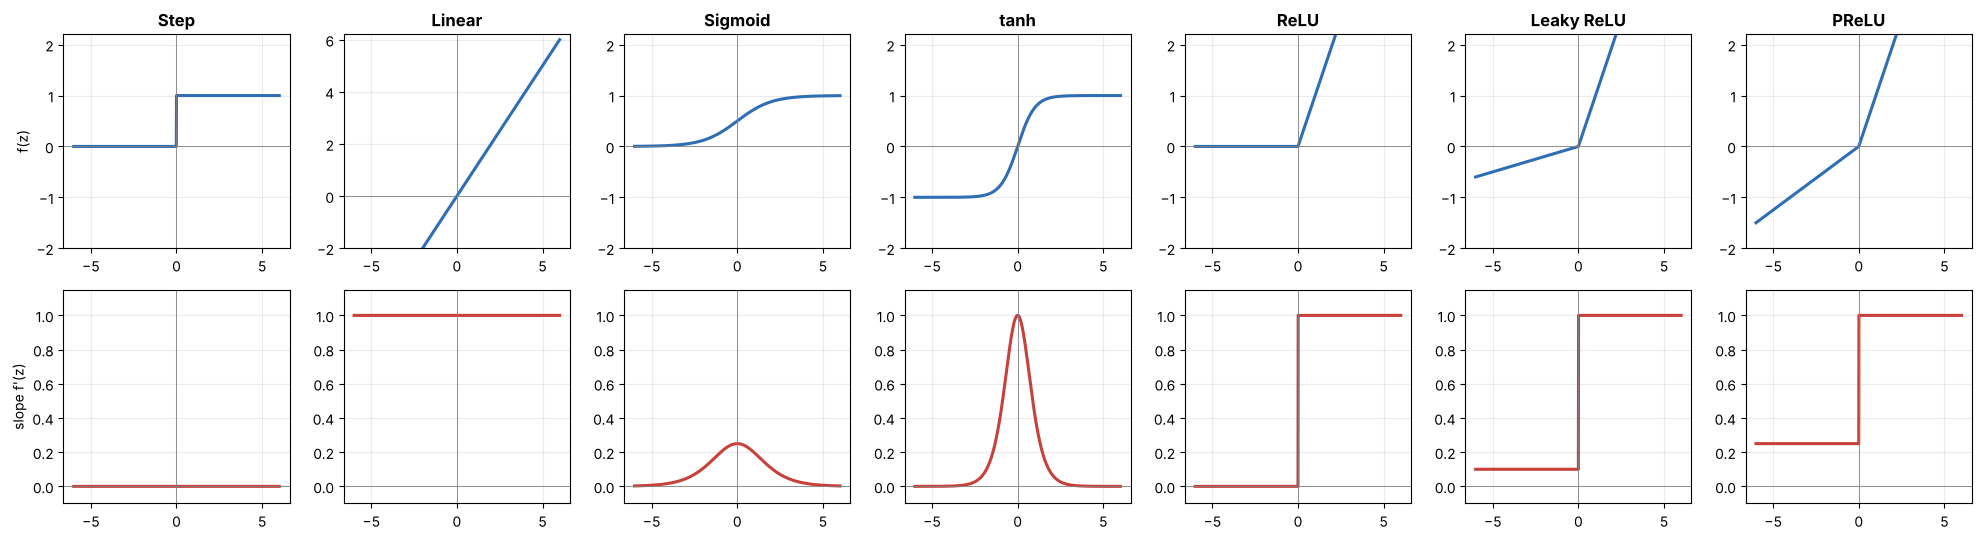

max sigmoid slope: 0.25  max tanh slope: 1.0


In [2]:
z = np.linspace(-6, 6, 1201)
sig = 1 / (1 + np.exp(-z))
alpha, a_prelu = 0.1, 0.25      # alpha exaggerated (usual is 0.01) so the leak is visible; 0.25 = PyTorch's PReLU start value
funcs = {
    "Step":       ((z >= 0).astype(float),           np.zeros_like(z)),
    "Linear":     (z,                                np.ones_like(z)),
    "Sigmoid":    (sig,                              sig * (1 - sig)),
    "tanh":       (np.tanh(z),                       1 - np.tanh(z) ** 2),
    "ReLU":       (np.maximum(0, z),                 (z > 0).astype(float)),
    "Leaky ReLU": (np.where(z > 0, z, alpha * z),    np.where(z > 0, 1, alpha)),
    "PReLU":      (np.where(z > 0, z, a_prelu * z),  np.where(z > 0, 1, a_prelu)),
}
fig, axes = plt.subplots(2, 7, figsize=(20, 5.5))
for j, (name, (f, d)) in enumerate(funcs.items()):
    axes[0, j].plot(z, f, lw=2.2, color="#2f6db5"); axes[0, j].set_title(name, fontweight="bold")
    axes[1, j].plot(z, d, lw=2.2, color="#c8403a")
    for ax in axes[:, j]:
        ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6); ax.grid(alpha=0.25)
    axes[0, j].set_ylim(-2, 2.2 if name != "Linear" else 6.2)
    axes[1, j].set_ylim(-0.1, 1.15)
axes[0, 0].set_ylabel("f(z)"); axes[1, 0].set_ylabel("slope f'(z)")
plt.tight_layout(); plt.show()
print("max sigmoid slope:", round((sig * (1 - sig)).max(), 4), " max tanh slope:", round((1 - np.tanh(z) ** 2).max(), 4))

Read the **bottom row**. During training, backpropagation multiplies these slopes together layer after layer:
- **Step:** slope 0 everywhere, so there is no learning signal (why the perceptron rule isn't gradient descent).
- **Sigmoid:** slope at most **0.25**, and near 0 once |z| > 4 (saturation).
- **tanh:** slope up to **1** at zero, but also near 0 once saturated.
- **ReLU:** slope exactly **1** for positive z, but **0** for negative z (the dying-ReLU risk).
- **Leaky ReLU / PReLU:** never zero, so a small signal always gets through.

Useful values: σ(0) = 0.5 and tanh(0) = 0. **tanh is zero-centred, sigmoid is not.**

In [3]:
for v in [-3, -1, 0, 1, 3]:
    s = 1 / (1 + np.exp(-v))
    print(f"z = {v:>2}:  sigmoid = {s:.3f}  tanh = {np.tanh(v):+.3f}  ReLU = {max(0, v)}  LeakyReLU(0.01) = {v if v > 0 else 0.01 * v:+.2f}")

z = -3:  sigmoid = 0.047  tanh = -0.995  ReLU = 0  LeakyReLU(0.01) = -0.03
z = -1:  sigmoid = 0.269  tanh = -0.762  ReLU = 0  LeakyReLU(0.01) = -0.01
z =  0:  sigmoid = 0.500  tanh = +0.000  ReLU = 0  LeakyReLU(0.01) = +0.00
z =  1:  sigmoid = 0.731  tanh = +0.762  ReLU = 1  LeakyReLU(0.01) = +1.00
z =  3:  sigmoid = 0.953  tanh = +0.995  ReLU = 3  LeakyReLU(0.01) = +3.00


## 2 · Why linear layers alone are not enough (a proof in code)

Two linear layers: **W2·(W1·x + b1) + b2 = (W2·W1)·x + (W2·b1 + b2)**. That's just **one** linear layer. However many you stack, the network can only draw straight lines.

In [4]:
torch.manual_seed(1)
deep_linear = nn.Sequential(nn.Linear(2, 16), nn.Linear(16, 16), nn.Linear(16, 16), nn.Linear(16, 1))  # 4 layers, NO activation
# Collapse it into ONE equivalent linear layer
W, b = torch.eye(2), torch.zeros(2)
for layer in deep_linear:
    W, b = layer.weight @ W, layer.weight @ b + layer.bias
x = torch.randn(5, 2)
print("4-layer linear network:", deep_linear(x).detach().squeeze().numpy().round(4))
print("single collapsed layer:", (x @ W.T + b).detach().squeeze().numpy().round(4))
print("identical:", torch.allclose(deep_linear(x), x @ W.T + b, atol=1e-5))

4-layer linear network: [-0.1407 -0.2472 -0.2158 -0.044  -0.3272]
single collapsed layer: [-0.1407 -0.2472 -0.2158 -0.044  -0.3272]
identical: True


Now the practical consequence: train a deep **linear** network and a deep **ReLU** network on data that needs a curved boundary (two interleaving half-moons).

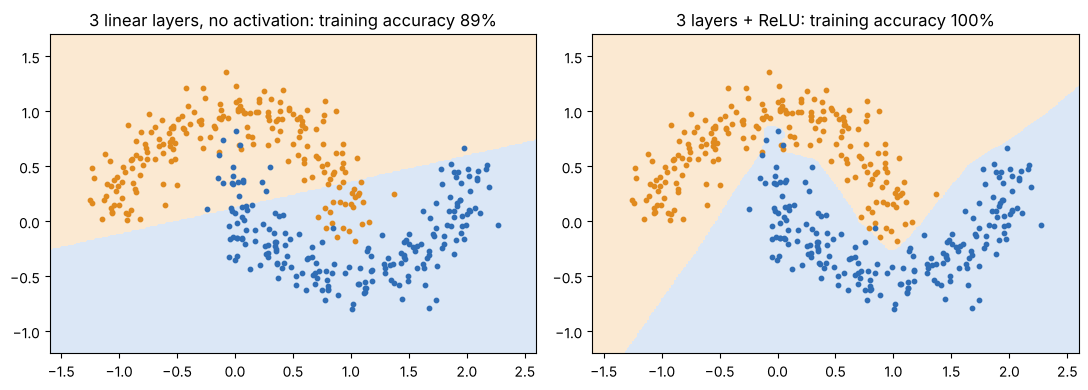

In [5]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(400, noise=0.15, random_state=0)
Xm_t, ym_t = torch.tensor(Xm, dtype=torch.float32), torch.tensor(ym, dtype=torch.float32).unsqueeze(1)

def make_net(act, depth=3, width=32):
    layers, d_in = [], 2
    for _ in range(depth):
        layers += [nn.Linear(d_in, width)] + ([act()] if act else [])
        d_in = width
    return nn.Sequential(*layers, nn.Linear(d_in, 1))

def train_bin(net, X, y, epochs=600, lr=0.01):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for _ in range(epochs):
        loss = nn.functional.binary_cross_entropy_with_logits(net(X), y)
        opt.zero_grad(); loss.backward(); opt.step()
    return ((net(X) > 0).float() == y).float().mean().item()

g = np.linspace(-1.6, 2.6, 200); GX, GY = np.meshgrid(g, np.linspace(-1.2, 1.7, 200))
grid = torch.tensor(np.column_stack([GX.ravel(), GY.ravel()]), dtype=torch.float32)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, act) in zip(axes, [("3 linear layers, no activation", None), ("3 layers + ReLU", nn.ReLU)]):
    torch.manual_seed(0); net = make_net(act)
    acc = train_bin(net, Xm_t, ym_t)
    Z = (net(grid) > 0).float().detach().numpy().reshape(GX.shape)
    ax.contourf(GX, GY, Z, levels=1, colors=["#fbe9d2", "#dbe7f6"])
    ax.scatter(*Xm[ym == 0].T, s=10, c="#e08a1e"); ax.scatter(*Xm[ym == 1].T, s=10, c="#2f6db5")
    ax.set_title(f"{name}: training accuracy {acc:.0%}")
plt.tight_layout(); plt.show()

Without an activation, the "deep" network can only draw a **straight line**. With ReLU it bends around the moons.

## 3 · Vanishing gradients: measured

A deep stack of layers. We send one batch through it, backpropagate, and measure how big the gradient is at the **first** layer, compared with the last layer. We try two ways of choosing the starting weights:
- **PyTorch's default** initialisation, used for every activation;
- the **matching** initialisation that practitioners pair with each activation: **He (Kaiming)** for ReLU and **Xavier (Glorot)** for sigmoid and tanh. These scale the random starting weights so the signal neither shrinks nor explodes from layer to layer.

 default init, Sigmoid: 2 layers 2e-04  5 layers 3e-07  10 layers 2e-11  20 layers 1e-19  30 layers 5e-29
 default init,    tanh: 2 layers 5e-02  5 layers 2e-03  10 layers 2e-04  20 layers 1e-06  30 layers 6e-10
 default init,    ReLU: 2 layers 2e-02  5 layers 2e-03  10 layers 4e-05  20 layers 5e-09  30 layers 5e-13
 matched init, Sigmoid: 2 layers 3e-04  5 layers 2e-06  10 layers 2e-09  20 layers 2e-15  30 layers 5e-22
 matched init,    tanh: 2 layers 2e-02  5 layers 2e-02  10 layers 4e-02  20 layers 4e-02  30 layers 3e-01
 matched init,    ReLU: 2 layers 8e-03  5 layers 6e-03  10 layers 2e-02  20 layers 1e-02  30 layers 3e-02


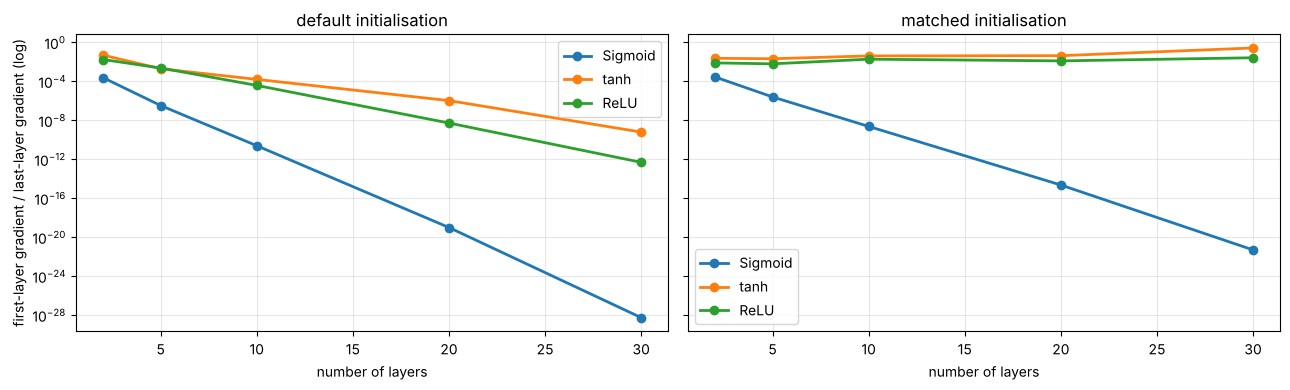

In [6]:
def first_layer_grad(act, depth, init="default", width=64, seed=0):
    torch.manual_seed(seed)
    layers = []
    for _ in range(depth):
        lin = nn.Linear(width, width)
        if init == "matched":
            if act is nn.ReLU:
                nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")          # He initialisation
            else:
                gain = nn.init.calculate_gain("tanh" if act is nn.Tanh else "sigmoid")
                nn.init.xavier_normal_(lin.weight, gain=gain)                     # Xavier initialisation
            nn.init.zeros_(lin.bias)
        layers += [lin, act()]
    net = nn.Sequential(*layers, nn.Linear(width, 1))
    x = torch.randn(256, width)
    net(x).pow(2).mean().backward()
    return net[0].weight.grad.abs().mean().item() / net[-1].weight.grad.abs().mean().item()

depths = [2, 5, 10, 20, 30]
acts = {"Sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "ReLU": nn.ReLU}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, init in zip(axes, ["default", "matched"]):
    for name, a in acts.items():
        r = [first_layer_grad(a, d, init) for d in depths]
        ax.semilogy(depths, r, "o-", label=name, lw=2)
        print(f"{init:>8} init, {name:>7}: " + "  ".join(f"{d} layers {v:.0e}" for d, v in zip(depths, r)))
    ax.set_title(f"{init} initialisation"); ax.set_xlabel("number of layers"); ax.grid(alpha=0.3, which="both"); ax.legend()
axes[0].set_ylabel("first-layer gradient / last-layer gradient (log)")
plt.tight_layout(); plt.show()

**What it shows:**
- **Sigmoid vanishes either way.** With matched initialisation, the gradient reaching layer 1 of a 30-layer net is still only about 10⁻²² of the last layer's, so those early layers can't learn. Its slope is at most 0.25, and multiplying 30 such factors together is hopeless. This is the lecture's **vanishing-gradient problem**.
- **tanh and ReLU need the matching initialisation.** With PyTorch's default starting weights, both also lose most of the signal as depth grows (ReLU at least as badly as tanh here). With **He for ReLU and Xavier for tanh**, the gradient stays roughly level even at 30 layers.

> **Lesson:** "ReLU fixes vanishing gradients" is half the story. ReLU's slope of 1 *allows* the signal to survive, but only with sensible starting weights (He initialisation). Standard models pair them for you, and add normalisation layers (notebook 05).

## 4 · Dying ReLU

A ReLU neuron whose input is negative for **every** example outputs 0 and has slope 0. It gets **no gradient, ever again**: it is **dead**.

### 4a · One neuron, seen up close
We teach a single neuron the function y = x on inputs 0…1, starting from a badly negative bias (b = −2), so z = w·x + b < 0 for every input.

In [7]:
x1 = torch.linspace(0, 1, 50).unsqueeze(1); target = x1.clone()
for name, f in [("ReLU", torch.relu), ("Leaky ReLU (alpha 0.01)", lambda t: nn.functional.leaky_relu(t, 0.01))]:
    w = torch.tensor([1.0], requires_grad=True); b = torch.tensor([-2.0], requires_grad=True)
    opt = torch.optim.SGD([w, b], lr=0.5)
    for step_i in range(2001):
        loss = ((f(x1 * w + b) - target) ** 2).mean()
        opt.zero_grad(); loss.backward()
        if step_i in (0, 2000):
            print(f"{name:>23} step {step_i:4d}: loss {loss.item():.4f}  bias {b.item():+.3f}  gradient on bias {b.grad.item():+.1e}")
        opt.step()

                   ReLU step    0: loss 0.3367  bias -2.000  gradient on bias +0.0e+00


                   ReLU step 2000: loss 0.3367  bias -2.000  gradient on bias +0.0e+00
Leaky ReLU (alpha 0.01) step    0: loss 0.3502  bias -2.000  gradient on bias -1.0e-02


Leaky ReLU (alpha 0.01) step 2000: loss 0.0000  bias -0.000  gradient on bias +6.3e-09


- **ReLU:** the gradient is **exactly 0**, at step 0 and still at step 2000. Nothing ever changes, and the neuron is permanently dead.
- **Leaky ReLU:** a small but non-zero gradient keeps nudging the bias up until the neuron comes back to life and fits the data (loss → 0).

### 4b · A whole network with most neurons knocked out
Imagine a bad update (or a bad start) has pushed every hidden bias to −0.35. We count the neurons that are never positive for any training image, then train with plain SGD.

In [8]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()
Xd = digits.data / 16.0; yd = digits.target
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.3, random_state=0, stratify=yd)
Xtr, Xte = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(Xte, dtype=torch.float32)
ytr, yte = torch.tensor(ytr), torch.tensor(yte)

def digit_net(act, depth=3, width=64, bias=None, init="default"):
    layers, d_in = [], 64
    for _ in range(depth):
        lin = nn.Linear(d_in, width)
        if init == "he":
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu"); nn.init.zeros_(lin.bias)
        if bias is not None:
            nn.init.constant_(lin.bias, bias)
        layers += [lin, act()]; d_in = width
    return nn.Sequential(*layers, nn.Linear(d_in, 10))

def train_digits(net, lr, epochs=40, opt_name="sgd"):
    opt = torch.optim.SGD(net.parameters(), lr=lr) if opt_name == "sgd" else torch.optim.Adam(net.parameters(), lr=lr)
    for _ in range(epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 64):
            idx = perm[i:i + 64]
            loss = nn.functional.cross_entropy(net(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (net(Xte).argmax(1) == yte).float().mean().item()

def never_positive(net, X):
    """share of hidden neurons whose output is <= 0 for EVERY input"""
    count, total, h = 0, 0, X
    with torch.no_grad():
        for layer in net[:-1]:
            h = layer(h)
            if not isinstance(layer, nn.Linear):
                count += (h <= 0).all(dim=0).sum().item(); total += h.shape[1]
    return count / total

print(f"{'activation':>23} {'never positive: before':>23} {'after':>6} {'test acc':>9}")
for name, act in [("ReLU", nn.ReLU), ("Leaky ReLU (alpha 0.01)", lambda: nn.LeakyReLU(0.01)),
                  ("Leaky ReLU (alpha 0.1)", lambda: nn.LeakyReLU(0.1)), ("PReLU (learned slope)", nn.PReLU)]:
    torch.manual_seed(0); net = digit_net(act, bias=-0.35)
    before = never_positive(net, Xtr)
    acc = train_digits(net, lr=0.1, epochs=60)
    print(f"{name:>23} {before:>23.0%} {never_positive(net, Xtr):>6.0%} {acc:>9.1%}")

             activation  never positive: before  after  test acc


                   ReLU                     77%    77%     10.2%


Leaky ReLU (alpha 0.01)                     77%    77%     10.2%


 Leaky ReLU (alpha 0.1)                     77%    77%     10.2%


  PReLU (learned slope)                     77%     0%     97.8%


**Honest reading:**
- **ReLU** stays stuck at chance (about 10% for 10 digits). Its dead neurons never recover.
- **Leaky ReLU with a fixed slope** does have a non-zero gradient, as the lecture says, and 4a showed that saves a single neuron. But here the signal must pass through **three** leaky layers (0.01 × 0.01 × 0.01), so with plain SGD and 60 epochs this network **also** stayed stuck, even with a 10× bigger slope (α = 0.1). "Reduces the risk" is not "removes the risk".
- **PReLU** learned to **change its slope** and escaped completely, reaching high accuracy. This is the flexibility the lecture credits it with.

### PReLU's learned slopes (normal start, normal training)

In [9]:
torch.manual_seed(0); net = digit_net(nn.PReLU); acc = train_digits(net, 0.1)
slopes = [m.weight.item() for m in net if isinstance(m, nn.PReLU)]
print("PReLU negative slopes: start 0.25 each -> learned:", [round(s, 3) for s in slopes], f"  (test acc {acc:.1%})")

PReLU negative slopes: start 0.25 each -> learned: [1.794, 1.341, 2.062]   (test acc 94.8%)


Each PReLU layer has one extra trainable number (its negative-side slope `a`), starting at 0.25, and training moved them. A learned slope can even end up **above 1**: nothing forces it to stay small, so the network picks whatever helps. With `nn.PReLU(num_parameters=width)` you get one slope **per neuron**, which is more flexible but adds more parameters (the lecture's overfitting caveat).

## 5 · A fair comparison: the same network, each activation

A 6-hidden-layer network on digits, trained identically (Adam, lr 0.001, 30 epochs), averaged over 3 seeds. First all with **PyTorch's default initialisation**, then ReLU again with **He initialisation**.

In [10]:
for name, act in [("Sigmoid", nn.Sigmoid), ("tanh", nn.Tanh), ("ReLU", nn.ReLU), ("LeakyReLU", lambda: nn.LeakyReLU(0.01)), ("PReLU", nn.PReLU)]:
    accs = []
    for seed in range(3):
        torch.manual_seed(seed); net = digit_net(act, depth=6)
        accs.append(train_digits(net, 1e-3, epochs=30, opt_name="adam"))
    print(f"{name:>15}: test accuracy {np.mean(accs):.1%} ± {np.std(accs):.1%}")
accs = []
for seed in range(3):
    torch.manual_seed(seed); net = digit_net(nn.ReLU, depth=6, init="he")
    accs.append(train_digits(net, 1e-3, epochs=30, opt_name="adam"))
print(f"{'ReLU + He init':>15}: test accuracy {np.mean(accs):.1%} ± {np.std(accs):.1%}")

        Sigmoid: test accuracy 27.3% ± 6.0%


           tanh: test accuracy 95.2% ± 0.7%


           ReLU: test accuracy 91.0% ± 2.4%


      LeakyReLU: test accuracy 93.1% ± 1.9%


          PReLU: test accuracy 94.6% ± 0.2%


 ReLU + He init: test accuracy 96.9% ± 0.5%


**Honest reading of these numbers:**
- **Sigmoid fails badly** at 6 layers (around 27%, near chance for 10 classes): that's the vanishing gradient in practice.
- With PyTorch's **default** initialisation, **tanh** (95.2%) actually beat plain **ReLU** (91.0%), with Leaky ReLU (93.1%) and PReLU (94.6%) in between.
- Give ReLU its matching **He initialisation** and it becomes the **best of all (96.9%)**, as section 3 predicted.
- **Takeaway:** "use ReLU" really means "use ReLU **with He initialisation**". Any ranking of activations depends on the setup (initialisation, optimiser, depth, data), so compare on your own validation data, as the lecture's summary says.

## 6 · Part 3 (13-08 lecture): ELU, GELU, Swish/SiLU and Softmax

| Function | Formula | Negative side |
|---|---|---|
| **ELU** | z if z > 0, else α·(eᶻ − 1) (α = 1 by default) | smooth curve, levels off at **−α** |
| **GELU** | z·Φ(z), where Φ = the standard normal CDF | small negative dip, then → 0 |
| **Swish / SiLU** | z·σ(z) | small negative dip, then → 0 |
| **Softmax** | pᵢ = e^{zᵢ} / Σⱼ e^{zⱼ}, applied to a **vector** | (not an element-wise activation) |

GELU and SiLU are "soft" ReLUs: instead of a hard switch at 0, they multiply z by a number between 0 and 1 that grows smoothly with z (Φ(z) or σ(z)). That's the lecture's "**softly gates** inputs rather than hard-thresholding them".

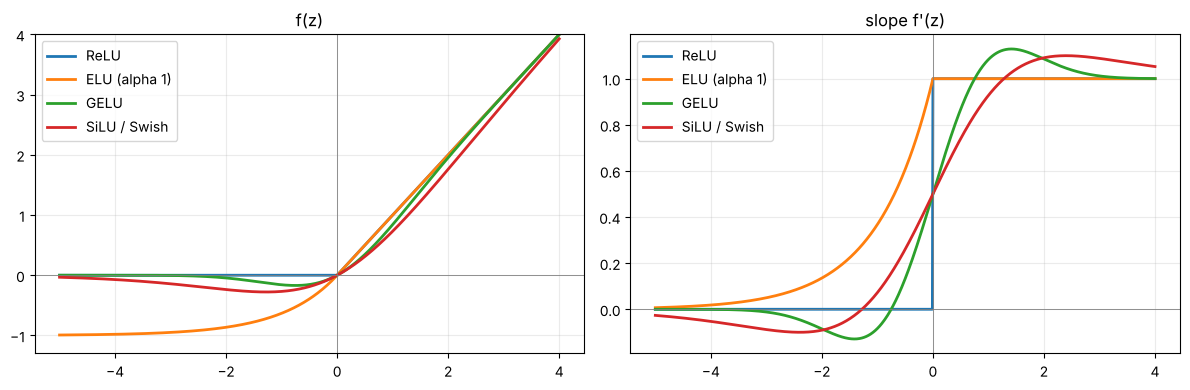

z             : [-3.0, -1.0, -0.5, 0.0, 0.5, 1.0, 3.0]
ReLU          : [0.0, 0.0, 0.0, 0.0, 0.5, 1.0, 3.0]
ELU (alpha 1) : [-0.95, -0.632, -0.393, 0.0, 0.5, 1.0, 3.0]
GELU          : [-0.004, -0.159, -0.154, 0.0, 0.346, 0.841, 2.996]
SiLU / Swish  : [-0.142, -0.269, -0.189, 0.0, 0.311, 0.731, 2.858]
lowest GELU value: -0.170 at z = -0.75
lowest SiLU / Swish value: -0.278 at z = -1.28
ELU at z = -10: -0.99995 (bounded below by -alpha = -1)


In [11]:
zt = torch.linspace(-5, 4, 901, requires_grad=True)
new_funcs = {"ReLU": torch.relu, "ELU (alpha 1)": nn.functional.elu, "GELU": nn.functional.gelu, "SiLU / Swish": nn.functional.silu}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, f in new_funcs.items():
    out = f(zt); (grad,) = torch.autograd.grad(out.sum(), zt)
    axes[0].plot(zt.detach(), out.detach(), lw=2, label=name); axes[1].plot(zt.detach(), grad, lw=2, label=name)
for ax, t in zip(axes, ["f(z)", "slope f'(z)"]):
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6); ax.grid(alpha=0.25); ax.set_title(t); ax.legend()
axes[0].set_ylim(-1.3, 4); plt.tight_layout(); plt.show()

zz = torch.tensor([-3.0, -1.0, -0.5, 0.0, 0.5, 1.0, 3.0])
print("z             :", zz.tolist())
for name, f in new_funcs.items():
    print(f"{name:<14}:", [round(v, 3) for v in f(zz).tolist()])
zfine = torch.linspace(-5, 0, 50001)
for name in ["GELU", "SiLU / Swish"]:
    v = new_funcs[name](zfine); i = v.argmin()
    print(f"lowest {name} value: {v[i].item():.3f} at z = {zfine[i].item():.2f}")
print("ELU at z = -10:", round(nn.functional.elu(torch.tensor(-10.0)).item(), 5), "(bounded below by -alpha = -1)")

**What to notice:**
- **ELU** equals ReLU for z > 0, but for z < 0 it curves smoothly down towards **−1** (= −α), so it can output negative values and its slope never drops to exactly 0.
- **GELU** and **SiLU** dip slightly below zero (lowest values about −0.17 and −0.28) and then return towards 0. Going down and then up means they are **non-monotonic**, which the lecture lists for Swish (GELU has the same property).
- All three are **smooth at 0** (no corner), unlike ReLU.
- **GELU** is the activation inside BERT and GPT-style Transformer feed-forward blocks. **SiLU** appears in, for example, EfficientNet and LLaMA's feed-forward blocks (as part of SwiGLU).

### Softmax: the lecture's example
Logits: cat 2.5, dog 1.2, horse 0.3.

In [12]:
logits = torch.tensor([2.5, 1.2, 0.3])
p = torch.softmax(logits, dim=0)
for name, zv, pv in zip(["cat", "dog", "horse"], logits.tolist(), p.tolist()):
    print(f"{name:<6} logit {zv:<4.1f} -> e^z = {np.exp(zv):6.3f} -> probability {pv:.3f}")
print("sum of probabilities:", round(p.sum().item(), 6))

cat    logit 2.5  -> e^z = 12.182 -> probability 0.723
dog    logit 1.2  -> e^z =  3.320 -> probability 0.197
horse  logit 0.3  -> e^z =  1.350 -> probability 0.080
sum of probabilities: 1.0


The probabilities are **0.723 / 0.197 / 0.080**. (The lecture's table rounds them to 0.73 / 0.20 / **0.07**; the correct rounding for horse is **0.08**, and only then do they sum to 1.)

### Numerically stable softmax
e^z overflows for large z (e^1000 is infinity in floating point). The fix: subtract the largest logit first. This gives exactly the same answer, because the common factor e^{−max} cancels top and bottom.

In [13]:
big = np.array([1000.0, 999.0, 998.0])
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp(big) / np.exp(big).sum()
stable = np.exp(big - big.max()) / np.exp(big - big.max()).sum()
print("naive  softmax:", naive)
print("stable softmax:", stable.round(4))
print("torch.softmax :", torch.softmax(torch.tensor(big), 0).numpy().round(4), "(built-ins are already stable)")

naive  softmax: [nan nan nan]
stable softmax: [0.6652 0.2447 0.09  ]
torch.softmax : [0.6652 0.2447 0.09  ] (built-ins are already stable)


This is why the lecture says "use numerically stable implementations": use `torch.softmax` / `F.cross_entropy` rather than writing `exp(z) / exp(z).sum()` yourself.

### Multi-class vs multi-label: softmax or independent sigmoids?
- **Single-label** (exactly one answer: cat *or* dog *or* horse) → **softmax**: the classes compete and the probabilities sum to 1.
- **Multi-label** (several can be true: a photo containing a cat *and* a dog) → **one sigmoid per label**: each is an independent yes/no.

In [14]:
scores = torch.tensor([3.0, 2.8, -2.0])          # a photo that clearly has a cat AND a dog, no horse
print("softmax (classes compete):", torch.softmax(scores, 0).numpy().round(3), " sum =", round(torch.softmax(scores, 0).sum().item(), 3))
print("sigmoids (independent)   :", torch.sigmoid(scores).numpy().round(3))

softmax (classes compete): [0.548 0.449 0.004]  sum = 1.0
sigmoids (independent)   : [0.953 0.943 0.119]


Softmax **forces** cat and dog to share the probability (0.548 and 0.449), so neither looks certain, even though both are present. Independent sigmoids say "cat: yes (0.953), dog: yes (0.943), horse: no (0.119)". Use sigmoids (with BCE, notebook 06) for multi-label.

### ReLU sparsity: the lecture's example

In [15]:
inp = torch.tensor([-3.0, -1.0, 0.5, 2.0, -4.0, 1.0])
out = torch.relu(inp)
print("input :", inp.tolist()); print("ReLU  :", out.tolist())
print(f"exact zeros: {(out == 0).sum().item()} of {len(out)}")
torch.manual_seed(0)
h = torch.relu(digit_net(nn.ReLU)[0](Xtr))      # first hidden layer of an untrained digits network
print(f"in a real (untrained) ReLU layer on the digits: {(h == 0).float().mean().item():.0%} of the activations are exactly 0")

input : [-3.0, -1.0, 0.5, 2.0, -4.0, 1.0]
ReLU  : [0.0, 0.0, 0.5, 2.0, 0.0, 1.0]
exact zeros: 3 of 6
in a real (untrained) ReLU layer on the digits: 51% of the activations are exactly 0


"Sparse" means **many outputs are exactly zero**: 3 of 6 here, and 51% in a real untrained layer. Only some neurons "fire" for each input, which is cheap to compute and often makes the features easier to separate.

### How do ELU, GELU and SiLU do on our digits benchmark?
Same setup as section 5 (6 hidden layers, Adam, lr 0.001, 30 epochs, 3 seeds, PyTorch default initialisation).

In [16]:
for name, act in [("ELU", nn.ELU), ("GELU", nn.GELU), ("SiLU", nn.SiLU)]:
    accs = []
    for seed in range(3):
        torch.manual_seed(seed); net = digit_net(act, depth=6)
        accs.append(train_digits(net, 1e-3, epochs=30, opt_name="adam"))
    print(f"{name:>15}: test accuracy {np.mean(accs):.1%} ± {np.std(accs):.1%}")

            ELU: test accuracy 95.1% ± 0.5%


           GELU: test accuracy 93.4% ± 1.6%


           SiLU: test accuracy 92.5% ± 1.5%


**Honest reading:** ELU 95.1%, GELU 93.4%, SiLU 92.5%. With the same default initialisation, all three beat plain ReLU (91.0%), and ELU matched tanh (95.2%). But none beat **ReLU + He initialisation (96.9%)**. On a small task like this, the newer activations are not automatically better: exactly the lecture's closing advice, "validate it on the actual task". (Differences of 1–2 points are within the seed-to-seed spread.)

### Choosing the output activation (lecture table)

| Task | Output activation | Why |
|---|---|---|
| binary classification | **sigmoid** | one probability between 0 and 1 |
| single-label multi-class | **softmax** | the probabilities form one distribution |
| multi-label | **one sigmoid per label** | independent yes/no decisions |
| unrestricted regression | **linear / identity** | the output can be any real number |
| positive-only regression (prices, counts) | often **softplus** (log(1 + eᶻ)) or another positive transform | guarantees a positive output |
| bounded regression | **scaled sigmoid / tanh** | restricts the output to a known interval |

## 7 · Which activation where (lecture summary, now with evidence)

| Situation | Use | Evidence in this notebook |
|---|---|---|
| hidden layers (default) | **ReLU** (+ He initialisation) | gradient stays level with He initialisation (section 3); best accuracy with He initialisation (section 5) |
| dying-ReLU concern | **Leaky ReLU** | revives a dead neuron (4a), but a small fixed slope may not rescue a badly broken deep net (4b) |
| want the leak learned | **PReLU** | learned its way out of 77% knocked-out neurons (4b) |
| bounded, zero-centred hidden state (RNN/LSTM) | **tanh** | tanh(0) = 0, range (−1, 1); strong with default initialisation (section 5) |
| binary classification output | **Sigmoid** | output in (0, 1), a probability; a poor hidden-layer choice (sections 3 and 5) |
| regression output | **Linear** | unbounded continuous output |
| classic perceptron only | **Step** | slope 0, so it can't be trained by gradient descent |
| smooth ReLU alternative with negative outputs | **ELU** | levels off at −α; smooth (section 6) |
| Transformer-style models | **GELU** | the standard choice in BERT/GPT feed-forward blocks |
| modern CNNs / LLM blocks that specify it | **Swish / SiLU** | smooth, non-monotonic (section 6) |
| single-label multi-class output | **Softmax** | probabilities summing to 1 (section 6) |
| multi-label output | **independent sigmoids** | softmax would force labels to compete (section 6) |

**The lecture's rule of thumb:** start with ReLU in ordinary hidden layers; if neurons die, try Leaky ReLU/PReLU and inspect the activations; use GELU or SiLU when the architecture calls for them; and **never choose an activation just because it's newer: validate it on your task**.

## ✅ Check yourself
1. What is the maximum slope of sigmoid, and why does that cause vanishing gradients in deep networks? *(0.25; multiplied over many layers it shrinks towards 0)*
2. Why can't a 10-layer network with linear activations learn the moons? *(it collapses to one linear layer, so a straight boundary)*
3. Vanishing gradient vs dying ReLU: what's the difference? *(vanishing = slopes small but non-zero, from saturating sigmoid/tanh; dying ReLU = slope exactly 0 because the input is always negative)*
4. Leaky ReLU vs PReLU? *(Leaky: fixed slope α chosen by you; PReLU: slope learned during training)*
5. Which activation would you put on the output of a house-price model? A spam detector? *(Linear; Sigmoid)*
6. Why is "ReLU solves vanishing gradients" only half true? *(ReLU's slope of 1 lets the signal through, but only with suitable initialisation, i.e. He; with poor starting weights the signal still shrinks)*
7. Softmax of logits (2, 0)? *(e² / (e² + 1) = 0.881 and 0.119)*
8. A photo can be tagged "beach", "sunset" and "people" at the same time. Softmax or sigmoids? *(independent sigmoids: it's multi-label)*
9. What is the lowest value ELU (α = 1) can output? *(it approaches −1 but never reaches it)*
10. Why subtract max(z) before computing softmax? *(prevents e^z overflowing; the answer is unchanged)*